In [12]:
import pandas as pd

In [13]:
extract = pd.read_csv('/home/kaira/Desktop/pipeline1/snps_pleiotropicos_ordenados.txt', sep=' ')
print(extract)
print(extract.columns)
# Método mais direto
extract.iloc[:, 0].to_csv('/home/kaira/Desktop/pipeline1/primeira_coluna.txt', 
                         index=False, 
                         header=False)

                  SNP  P_disease_1  P_disease_2  Fisher_P
0     7:150439500:T:C     0.001583     0.004219  0.002444
1      12:6094784:C:T     0.002243     0.010870  0.006528
2     19:49377436:C:G     0.007015     0.006928  0.010864
3     17:65739627:A:G     0.000071     0.785900  0.012019
4     19:59023174:G:A     0.012260     0.011080  0.022712
...               ...          ...          ...       ...
6391   6:31627523:C:T     1.000000     1.000000  1.000000
6392   7:97933601:C:T     1.000000     1.000000  1.000000
6393  9:129377855:C:G     1.000000     1.000000  1.000000
6394  9:140509075:C:A     1.000000     1.000000  1.000000
6395   9:96026243:A:G     1.000000     1.000000  1.000000

[6396 rows x 4 columns]
Index(['SNP', 'P_disease_1', 'P_disease_2', 'Fisher_P'], dtype='object')


In [37]:
# Calcular porcentagem para cada coluna
colunas = ['P_disease_1', 'P_disease_2', 'Fisher_P']

for coluna in colunas:
    # Contar valores ≤ 0.05
    count_menor_igual_005 = (extract[coluna] <= 0.05).sum()
    # Total de valores (excluindo NaN se houver)
    total_valores = extract[coluna].count()
    # Calcular porcentagem
    porcentagem = (count_menor_igual_005 / total_valores) * 100
    
    print(f"\nColuna {coluna}:")
    print(f"Valores ≤ 0.05: {count_menor_igual_005}")
    print(f"Total de valores: {total_valores}")
    print(f"Porcentagem: {porcentagem:.2f}%")

# Método alternativo mais conciso
print("\n--- Método conciso ---")
for coluna in colunas:
    porcentagem = (extract[coluna] <= 0.05).mean() * 100
    print(f"{coluna}: {porcentagem:.2f}% dos valores são ≤ 0.05")


Coluna P_disease_1:
Valores ≤ 0.05: 338
Total de valores: 6396
Porcentagem: 5.28%

Coluna P_disease_2:
Valores ≤ 0.05: 280
Total de valores: 6396
Porcentagem: 4.38%

Coluna Fisher_P:
Valores ≤ 0.05: 12
Total de valores: 6396
Porcentagem: 0.19%

--- Método conciso ---
P_disease_1: 5.28% dos valores são ≤ 0.05
P_disease_2: 4.38% dos valores são ≤ 0.05
Fisher_P: 0.19% dos valores são ≤ 0.05


In [14]:
snpvep = pd.read_csv("/home/kaira/Desktop/pipeline1/snps_pleiotropicos_ordenados_anotado_vep.txt", sep = "\t")
print(snpvep.head())
print(snpvep.shape)

/tmp/ipykernel_22018/4247232679.py:1: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  snpvep = pd.read_csv("/home/kaira/Desktop/pipeline1/snps_pleiotropicos_ordenados_anotado_vep.txt", sep = "\t")


  #Uploaded_variation            Location Allele  \
0      19:1388538:C:T  19:1388539-1388539      T   
1      19:1388538:C:T  19:1388539-1388539      T   
2      19:1388538:C:T  19:1388539-1388539      T   
3      19:1388538:C:T  19:1388539-1388539      T   
4      19:1388538:C:T  19:1388539-1388539      T   

                          Consequence    IMPACT  SYMBOL             Gene  \
0                    missense_variant  MODERATE  NDUFS7  ENSG00000115286   
1                    missense_variant  MODERATE  NDUFS7  ENSG00000115286   
2                    missense_variant  MODERATE  NDUFS7  ENSG00000115286   
3  non_coding_transcript_exon_variant  MODIFIER  NDUFS7  ENSG00000115286   
4             downstream_gene_variant  MODIFIER       -  ENSG00000248015   

  Feature_type             Feature          BIOTYPE  ...  \
0   Transcript  ENST00000233627.14   protein_coding  ...   
1   Transcript  ENST00000313408.11   protein_coding  ...   
2   Transcript   ENST00000414651.3   protein_codin

In [15]:
# Remover linhas duplicadas baseadas na coluna '#Uploaded_variation'
snpvep = snpvep.drop_duplicates(subset=['#Uploaded_variation'], keep='first')
print(snpvep.shape)

(1572, 675)


In [16]:
snp = pd.read_csv("/home/kaira/Desktop/github_pipeline1/pipeline1/snps_pleiotropicos.txt", sep="\t")
print(snp.head())
print(f'"before annotation" {snp.shape}')  
snp = snp.drop_duplicates(subset=['variants'], keep='first')
print(f'"after annotation" {snpvep.shape}') 

        variants
0  1:3410410:C:T
1  1:3417211:G:A
2  1:3511934:A:G
3  1:6279370:G:C
4  1:6529443:A:G
"before annotation" (1264, 1)
"after annotation" (1572, 675)


In [17]:
import pandas as pd
import numpy as np


# Identificando colunas com apenas '-'
# colunas_com_traco = ad.columns[(ad == '-').all()]

# Substituindo '-' por NaN nas colunas numéricas
snpvep['gnomAD4.1_joint_POPMAX_AF'] = snpvep['gnomAD4.1_joint_POPMAX_AF'].replace('-', np.nan)


# Convertendo as colunas para float
snpvep['gnomAD4.1_joint_POPMAX_AF'] = snpvep['gnomAD4.1_joint_POPMAX_AF'].astype(float)


# Criando a máscara para as linhas a serem removidas
mask = (snpvep['gnomAD4.1_joint_POPMAX_AF'] >= 0.01)

# Invertendo a máscara e filtrando o DataFrame
snpvep = snpvep[~mask]

# Mantendo apenas as colunas desejadas
# ad = ad.drop(colunas_com_traco, axis=1)
print(snpvep.shape)

(1568, 675)


In [18]:
import pandas as pd

# ... (seu código existente)

# Filtrando o DataFrame para as linhas de interesse
# df_filtrado = ad[(ad['gnomAD_exomes_POPMAX_AF'] >= 1) | (ad['gnomAD_genomes_POPMAX_AF'] >= 1)]

# Calculando o intervalo dos valores nas colunas de interesse
intervalo_exomes = snpvep['gnomAD4.1_joint_POPMAX_AF'].agg(['min', 'max'])


# Imprimindo os intervalos
print("Intervalo de valores para gnomAD4.1_joint_POPMAX_AF:")
print(intervalo_exomes)


Intervalo de valores para gnomAD4.1_joint_POPMAX_AF:
min    8.474220e-07
max    3.299240e-04
Name: gnomAD4.1_joint_POPMAX_AF, dtype: float64


In [19]:
import pandas as pd

# Supondo que você já tenha carregado seu DataFrame 'snpvep'

def encontrar_coluna_com_valor(df, valor):
  """
  Encontra a coluna em um DataFrame que contém o valor especificado.

  Args:
    df: O DataFrame a ser pesquisado.
    valor: O valor a ser encontrado.

  Returns:
    Uma lista com os nomes das colunas que contêm o valor, ou uma lista vazia se não for encontrado.
  """

  colunas_com_valor = []
  for coluna in df.columns:
    if valor in df[coluna].values:
      colunas_com_valor.append(coluna)
  return colunas_com_valor

# Encontrando a coluna com o valor 'benign(0.015)'
colunas = encontrar_coluna_com_valor(snpvep, 'benign(0.015)')

if colunas:
  print("A coluna(s) que contém o valor 'benign(0.015)' é(são):")
  print(colunas)
else:
  print("O valor 'benign(0.015)' não foi encontrado em nenhuma coluna.")

A coluna(s) que contém o valor 'benign(0.015)' é(são):
['PolyPhen']


In [20]:
import pandas as pd

# Supondo que você já tenha carregado seu DataFrame 'ad'

# Obtendo os valores únicos da coluna 'ClinPred'
valores_unicos = snpvep['PolyPhen'].unique()

# Imprimindo os valores únicos
print("Valores únicos na coluna 'PolyPhen':")
print(valores_unicos)

Valores únicos na coluna 'PolyPhen':
['-' 'possibly_damaging(0.704)' 'benign(0)' 'benign(0.33)' 'benign(0.167)'
 'probably_damaging(0.988)' 'probably_damaging(0.922)' 'benign(0.04)'
 'unknown(0)' 'benign(0.041)' 'probably_damaging(0.963)'
 'probably_damaging(0.965)' 'benign(0.003)' 'probably_damaging(0.991)'
 'benign(0.028)' 'benign(0.02)' 'probably_damaging(0.997)'
 'possibly_damaging(0.711)' 'benign(0.031)' 'possibly_damaging(0.81)'
 'benign(0.006)' 'probably_damaging(0.938)' 'benign(0.266)'
 'probably_damaging(0.986)' 'benign(0.01)' 'benign(0.007)'
 'possibly_damaging(0.545)' 'benign(0.179)' 'probably_damaging(0.998)'
 'probably_damaging(1)' 'benign(0.015)' 'probably_damaging(0.974)'
 'probably_damaging(0.993)' 'possibly_damaging(0.645)' 'benign(0.005)'
 'benign(0.134)' 'probably_damaging(0.911)' 'benign(0.001)']


In [21]:
import pandas as pd

# Supondo que você já tenha carregado seu DataFrame 'ad'

# Obtendo os valores únicos da coluna 'ClinPred'
valores_unicos = snpvep['ClinPred'].unique()

# Imprimindo os valores únicos
print("Valores únicos na coluna 'ClinPred':")
print(valores_unicos)

Valores únicos na coluna 'ClinPred':
['-' '0.752917587757111' '0.0884888536493508' '0.74057412147522'
 '0.43350828127311' '0.999897360801697' '0.98602157831192'
 '0.253861074983378' '0.0332543943423161' '0.198941931128502'
 '0.105481294770458' '0.585303544998169' '0.609748918577289'
 '0.0515023210770057' '0.993266820907593' '0.994066715240479'
 '0.0272100904066912' '0.0993961989879608' '0.982457220554352'
 '0.631864249706268' '0.0518560260633027' '0.0807870104908943'
 '0.2148419463106' '0.993869185447693' '0.710006713867188'
 '0.504317402839661' '0.306735274039556' '0.995170925976629'
 '0.924755930900574' '0.0373635925352573' '0.940154790878296'
 '0.833895862102509' '0.871474623680115' '0.999124228954315'
 '0.194940154012838' '0.772311091423035' '0.725470066070557'
 '0.999673962593079' '0.999120891094208' '0.690684914588928'
 '0.647669613361359' '0.795275509357452' '0.975710332393646'
 '0.121016539633274' '0.556961715221405' '0.0914058895927182'
 '0.999021291732788']


In [22]:
linhas_originais = len(snpvep)
snpvep = snpvep[~snpvep['PolyPhen'].str.contains('benign', case=False, na=False)]
linhas_removidas = linhas_originais - len(snpvep)
print(f"Linhas removidas: {linhas_removidas}")

Linhas removidas: 21


In [23]:
linhas_originais = len(snpvep)
snpvep = snpvep.drop_duplicates(subset=['#Uploaded_variation'], keep='first')
linhas_removidas = linhas_originais - len(snpvep)
print(f"Linhas removidas: {linhas_removidas}")

Linhas removidas: 0


In [24]:
print(snpvep.shape)


(1547, 675)


In [25]:
import pandas as pd

# Supondo que você já tenha carregado seu DataFrame 'ad'

# Obtendo os valores únicos da coluna 'ClinPred'
valores_unicos = snpvep['IMPACT'].unique()

# Imprimindo os valores únicos
print("Valores únicos na coluna 'IMPACT':")
print(valores_unicos)

Valores únicos na coluna 'IMPACT':
['MODIFIER' 'MODERATE' 'LOW' 'HIGH']


In [26]:
linhas_originais = len(snpvep)
snpvep = snpvep[~snpvep['IMPACT'].str.contains('LOW', case=False, na=False)]
linhas_removidas = linhas_originais - len(snpvep)
print(f"Linhas removidas: {linhas_removidas}")

Linhas removidas: 30


In [27]:
import pandas as pd

# Supondo que você já tenha carregado seu DataFrame 'ad'

# Obtendo os valores únicos da coluna 'ClinPred'
valores_unicos = snpvep['BLOSUM62'].unique()

# Imprimindo os valores únicos
print("Valores únicos na coluna 'BLOSUM62':")
print(valores_unicos)

Valores únicos na coluna 'BLOSUM62':
['-' '1' '-2' '0' '-1' '-3' '3' '2']


In [28]:

linhas_originais = len(snpvep)
# Usando regex para combinar '-1', '-2' ou '-3' (separados por |)
snpvep = snpvep[~snpvep['BLOSUM62'].str.contains(r'-1|-2|-3', case=False, na=False)]
linhas_removidas = linhas_originais - len(snpvep)
print(f"Linhas removidas: {linhas_removidas}")

Linhas removidas: 16


In [29]:
print(snpvep.shape)


(1501, 675)


In [30]:
import pandas as pd

# Supondo que você já tenha carregado seu DataFrame 'ad'

# Obtendo os valores únicos da coluna 'ClinPred'
valores_unicos = snpvep['Gene'].unique()

# Imprimindo os valores únicos
print("Valores únicos na coluna 'Gene':")
print(valores_unicos)

Valores únicos na coluna 'Gene':
['ENSG00000140873' 'ENSG00000168502' 'ENSG00000186094' ...
 'ENSG00000260220' 'ENSG00000107331' 'ENSG00000181090']


In [31]:
import pandas as pd

# Supondo que você já tenha carregado seu DataFrame 'ad'

# Obtendo os valores únicos da coluna 'ClinPred'
valores_unicos = snpvep['GO'].unique()

# Imprimindo os valores únicos
print("Valores únicos na coluna 'GO':")
print(valores_unicos)

Valores únicos na coluna 'GO':
['GO:0001654:eye_development,GO:0004222:metalloendopeptidase_activity,GO:0005576:extracellular_region,GO:0006508:proteolysis,GO:0008233:peptidase_activity,GO:0008237:metallopeptidase_activity,GO:0016787:hydrolase_activity,GO:0030198:extracellular_matrix_organization,GO:0031012:extracellular_matrix,GO:0046872:metal_ion_binding,GO:0090331:negative_regulation_of_platelet_aggregation'
 'GO:0000776:kinetochore,GO:0000922:spindle_pole,GO:0001578:microtubule_bundle_formation,GO:0003723:RNA_binding,GO:0005515:protein_binding,GO:0005615:extracellular_space,GO:0005737:cytoplasm,GO:0005856:cytoskeleton,GO:0005876:spindle_microtubule,GO:0005886:plasma_membrane,GO:0007059:chromosome_segregation,GO:0008017:microtubule_binding,GO:0010506:regulation_of_autophagy,GO:0016020:membrane,GO:0016324:,GO:0016327:,GO:0016328:,GO:0030496:midbody,GO:0042803:protein_homodimerization_activity,GO:0045197:establishment_or_maintenance_of_epithelial_cell_apical/basal_polarity,GO:0051301:

In [32]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


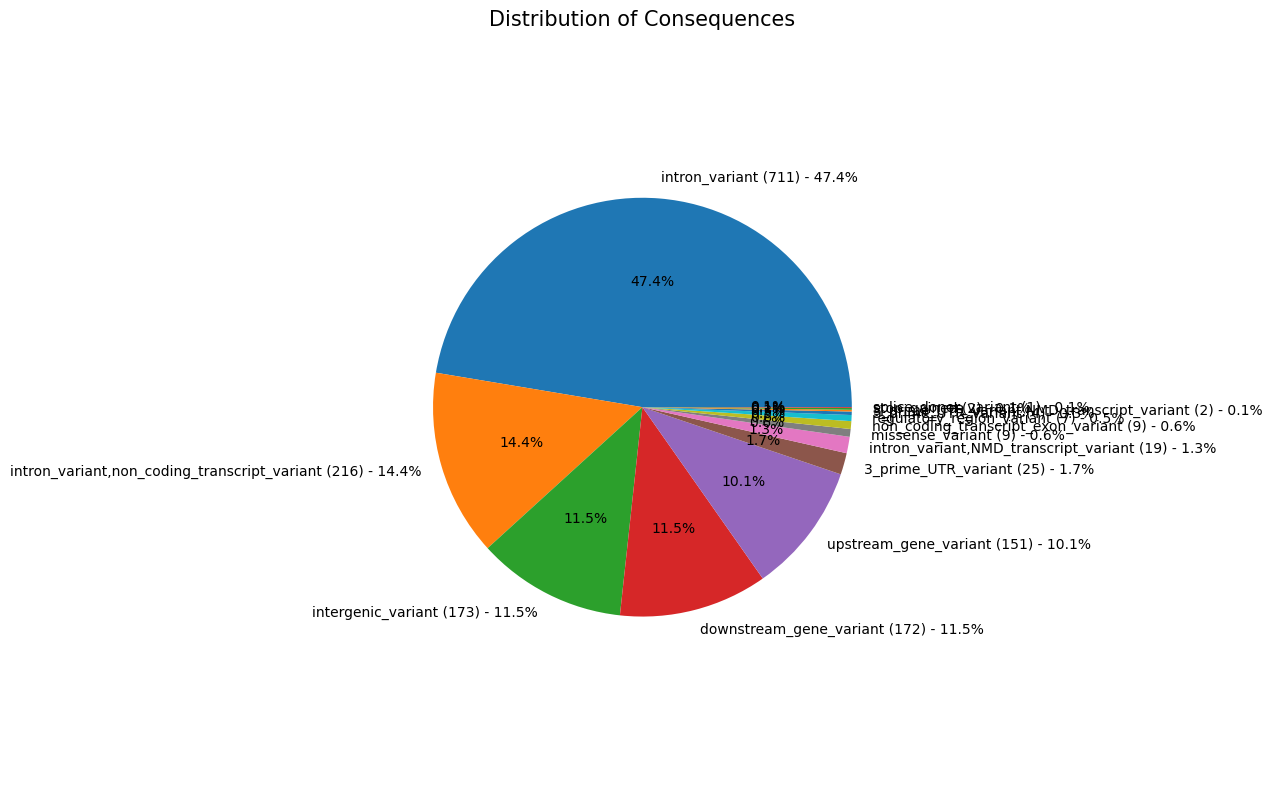

In [33]:
import matplotlib.pyplot as plt

# Conta a frequência de cada consequência
consequence_counts = snpvep['Consequence'].value_counts()

# Calcula as porcentagens
consequence_percentages = consequence_counts / len(snpvep) * 100

# Cria o gráfico de pizza
plt.figure(figsize=(12, 8))
plt.pie(consequence_counts, 
        labels=[f'{index} ({count}) - {percentage:.1f}%' 
                for index, count, percentage 
                in zip(consequence_counts.index, 
                       consequence_counts.values, 
                       consequence_percentages)],
        autopct='%1.1f%%')
plt.title('Distribution of Consequences', fontsize=15)
plt.axis('equal')  # Garante que o gráfico seja um círculo perfeito

# Mostra o gráfico
plt.tight_layout()
plt.show()

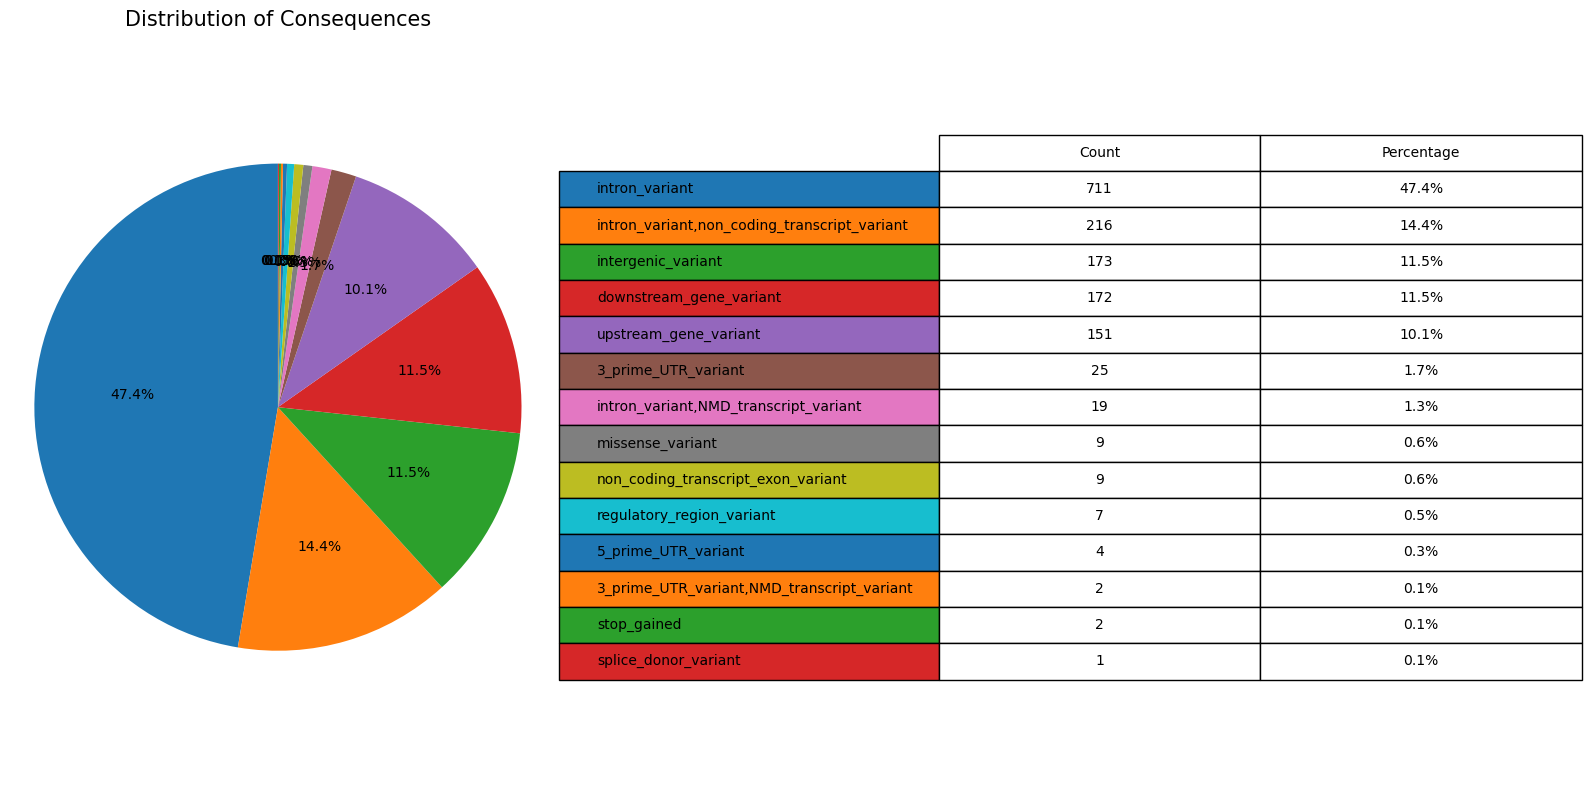

In [34]:
import matplotlib.pyplot as plt
import numpy as np

# Conta a frequência de cada consequência
consequence_counts = snpvep['Consequence'].value_counts()

# Calcula as porcentagens
consequence_percentages = consequence_counts / len(snpvep) * 100

# Cria o gráfico de pizza
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
fig.subplots_adjust(wspace=0.4)

# Gráfico de pizza
wedges, texts, autotexts = ax1.pie(consequence_counts.values, 
                                   autopct='%1.1f%%',
                                   startangle=90)
ax1.set_title('Distribution of Consequences', fontsize=15)
ax1.axis('equal')  # Garante que o gráfico seja um círculo perfeito

# Cria a tabela com as legendas
colors = [wedge.get_facecolor() for wedge in wedges]
cell_text = []
for count, percentage in zip(consequence_counts.values, consequence_percentages):
    cell_text.append([f'{count}', f'{percentage:.1f}%'])

# Remove o eixo da tabela
ax2.axis('off')

# Cria a tabela
table = ax2.table(cellText=cell_text,
                  rowLabels=consequence_counts.index,
                  rowColours=colors,
                  colLabels=['Count', 'Percentage'],
                  cellLoc='center',
                  loc='center')

# Ajusta o tamanho da fonte da tabela
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

# Mostra o gráfico
plt.tight_layout()
plt.show()

In [35]:
# Método mais direto
print("Valores da coluna SYMBOL diferentes de '-':")

# Filtrar os valores diferentes de '-'
valores_filtrados = snpvep[snpvep['SYMBOL'] != '-']['SYMBOL']

# Imprimir os valores
for valor in valores_filtrados:
    print(valor)

# Salvar em arquivo - CORREÇÃO PRINCIPAL
# Não podemos usar 'valor' que é uma string individual, mas sim a Series completa
valores_filtrados.to_csv('symbol.txt', sep='\t', index=False, header=False)


Valores da coluna SYMBOL diferentes de '-':
ADAMTS18
MTCL1
AGBL4
C1orf74
GIGYF1
PHF21A
OR10D4P
STK31
NOC2L
SSU72
PLCH2
PRDM16
LRRC47
RNF207
RERE
PEX14
VPS13D
PRAMEF7
FBLIM1
UQCRHL
UBR4
UBR4
RNU4-28P
MICOS10
EIF4G3
ELOA
FUCA1
LINC02800
NIPAL3
RHD
CRYBG2
RPS6KA1
GPATCH3
THEMIS2
TMEM39B
THRAP3
SH3D21
INPP5B
UTP11
LOC105378654
LOC105378669
SCMH1-DT
HIVEP3
MAST2
CYP4Z2P
AGBL4
GLIS1
GLIS1
TCEANC2
USP24
LINC01755
LINC01755
DOCK7
DOCK7-DT
ROR1
ROR1
PDE4B
PDE4B
GNG12
ST6GALNAC3
ZZZ3
GIPC2
LPAR3
SELENOF
SELENOF
TGFBR3
TGFBR3
RNPC3-DT
RNPC3
CELSR2
SORT1
ATXN7L2
LINC01525
HYDIN2
FALEC
CTSS
GABPB2
GABPB2
PIP5K1A
CCDST
CCDST
LCE1F
SPRR4
TDRD10
UBE2Q1
HDGF
INSRR
OR10AA1P
IFI16
IFI16
DUSP23
Y_RNA
ATF6
RGS5
RXRG
POU2F1
DCAF6
F5
F5
TNN
STX6
CACNA1E
CFHR4
ASCL5
PIK3C2B
LOC105371692
NFASC
IL24
LINC02942
LINC02942
CD46
HHAT
HHAT
LPGAT1-AS1
LOC105372916
LOC105372916
RAB3GAP2
BROX
RNU6-1319P
MRPL55
MRPL55
H2AC25
RNF187
RNF187
RNA5S3
C1orf198
DISC1
ARID4B
EDARADD
ACTN2
SMYD3
OR6R1P
OR2L6P
OR2L3
OR14I1
CALML3-

In [ ]:
snpvep.to_csv("snpvep_variants_Pleiotropy_filtradas.txt", sep = "\t")
